In [2]:
import pandas as pd

df = pd.read_csv("cars.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [5]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [7]:
df.duplicated().sum()

np.int64(1202)

In [8]:
df = df.drop_duplicates()
print(len(df))

6926


In [9]:
df.isna().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

## Handling Nulls

At first, I dropped all nulls from the dataset without checking what information was being lost. However, I realized it was important to examine which rows were being removed to ensure I wasn’t discarding potentially valuable or relevant data. By investigating the nulls, I could make more informed decisions about data cleaning while preserving the integrity and usefulness of the dataset.

In [10]:
df['fuel'].unique()

<StringArray>
['Diesel', 'Petrol', 'LPG', 'CNG']
Length: 4, dtype: str

In [11]:
df['seller_type'].unique()

<StringArray>
['Individual', 'Dealer', 'Trustmark Dealer']
Length: 3, dtype: str

In [12]:
df['owner'].unique()

<StringArray>
[         'First Owner',         'Second Owner',          'Third Owner',
 'Fourth & Above Owner',       'Test Drive Car']
Length: 5, dtype: str

## Brand Name Standardization

I created a new column to clarify and standardize the brand name. This step makes later analysis easier and more accurate, especially when exploring brand-specific quirks or trends. Having standardized brand names ensures consistent and reliable insights throughout the analysis.

In [13]:
df['brand'] = df['name'].str.split().str[0]
df['brand'] = df['brand'].replace({'Land': 'Land Rover'})
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti


In [14]:
df[["mileage"]].head()

,mileage
0,23.4 kmpl
1,21.14 kmpl
2,17.7 kmpl
3,23.0 kmpl
4,16.1 kmpl


## Plotting Price versus odometer reading

Plotting car price versus odometer reading shows the relationship between how much a car has been used and how much someone is asking for it. This can help me later determine which factors drive the selling price the most.

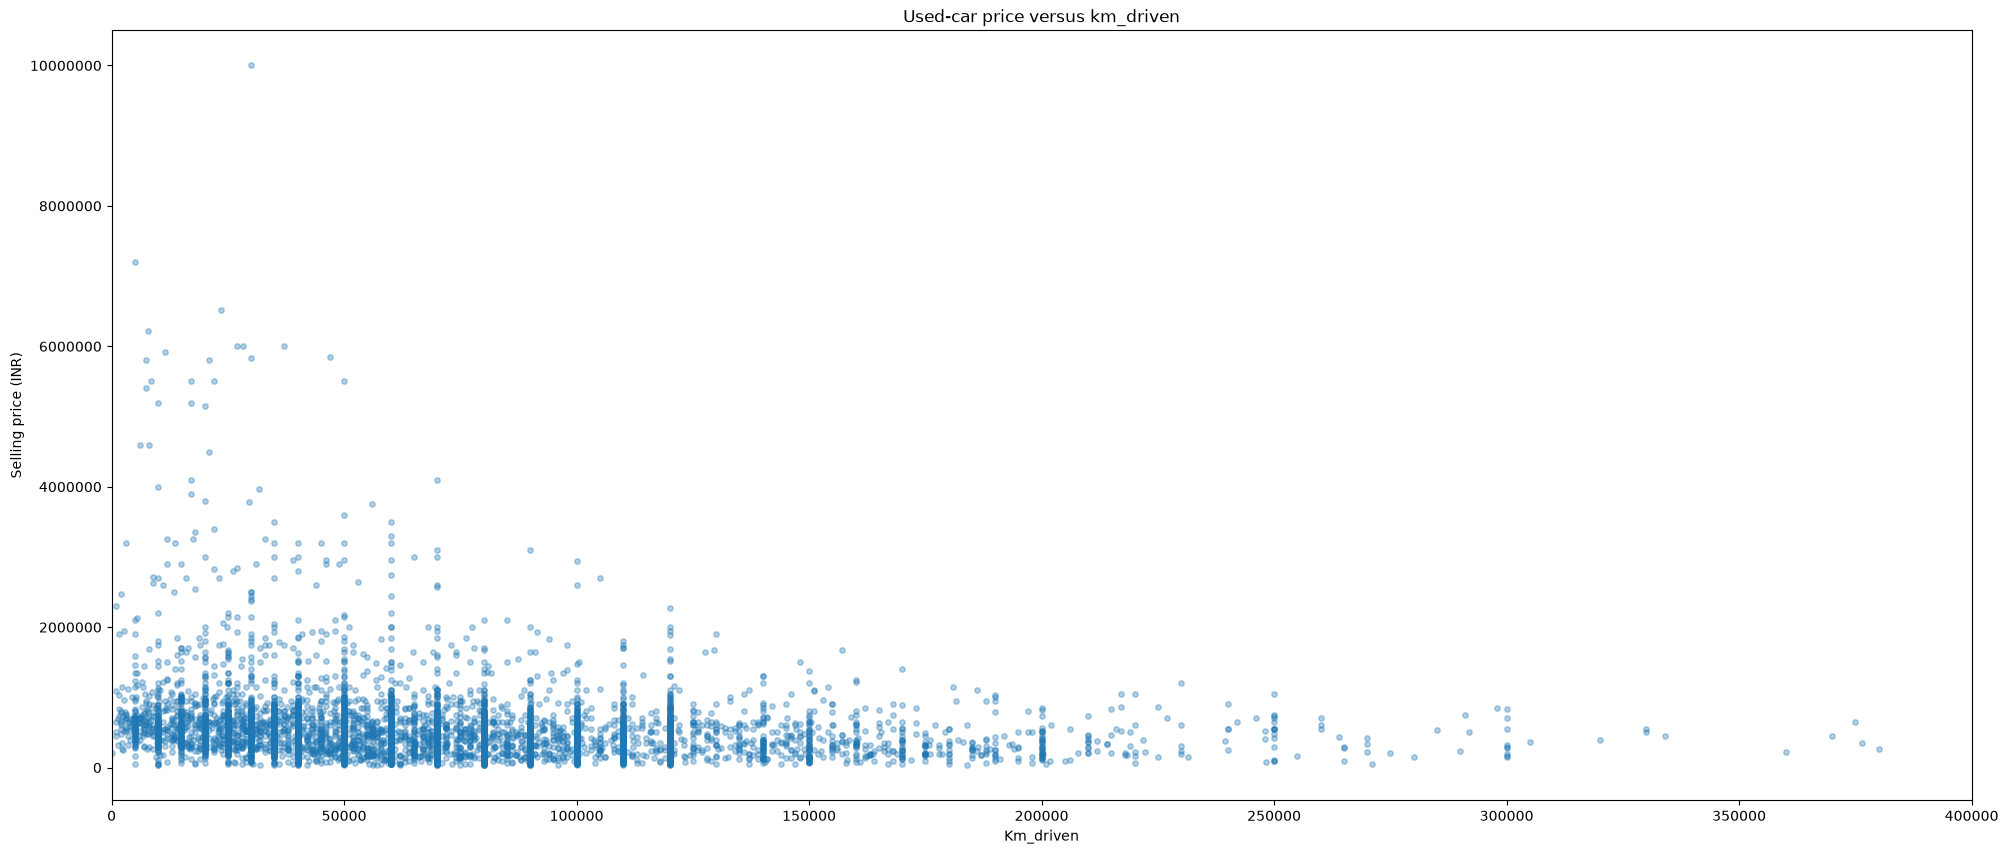

In [15]:
plot_data = df.dropna(subset=["km_driven", "selling_price"])

plt.figure(figsize=(24, 10))
plt.scatter(plot_data["km_driven"], plot_data["selling_price"], alpha=0.35, s=15)
plt.title("Used-car price versus km_driven")
plt.xlabel("Km_driven")
plt.ylabel("Selling_price")
plt.xlim(0, 400_000)
plt.ticklabel_format(axis="y", style="plain")
plt.ylabel("Selling price (INR)")
plt.show()

## Edit Notes

Currency and Unit Assumptions

After plotting the initial chart, I noticed the dataset didn’t specify what currency the selling price was in. The Kaggle page lacked this information, but after some research, I determined that prices are most likely listed in Indian rupees. Later in the project, I plan to convert all monetary values to USD and all distance measurements to Miles, ensuring the analysis is more accessible and relevant for Western audiences.

In [16]:
df.brand.unique()

array(['Maruti', 'Skoda', 'Honda', 'Hyundai', 'Toyota', 'Ford', 'Renault',
       'Mahindra', 'Tata', 'Chevrolet', 'Fiat', 'Datsun', 'Jeep',
       'Mercedes-Benz', 'Mitsubishi', 'Audi', 'Volkswagen', 'BMW',
       'Nissan', 'Lexus', 'Jaguar', 'Land Rover', 'MG', 'Volvo', 'Daewoo',
       'Kia', 'Force', 'Ambassador', 'Ashok', 'Isuzu', 'Opel', 'Peugeot'],
      dtype=object)

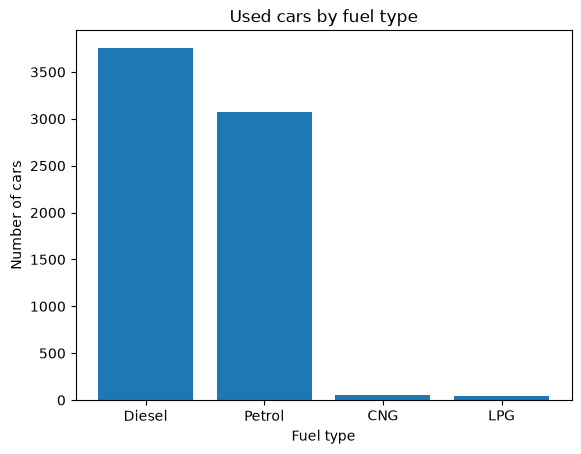

In [17]:
fuel_counts = df["fuel"].value_counts()

plt.bar(fuel_counts.index, fuel_counts.values)
plt.title("Used cars by fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Number of cars")
plt.savefig("used_cars_by_fuel_type.png", dpi=300, bbox_inches="tight")
plt.show()

## Discovery Note

Fuel Type Observation

I created this chart after noticing an unexpectedly high number of diesel-powered vehicles in the dataset. To my surprise, diesel vehicles actually outnumber all other fuel types—a notable finding that may influence later analysis.

In [18]:
summary = df.groupby("brand")["selling_price"].median()

summary = summary.sort_values(ascending=False)

summary

brand
Lexus            5150000.0
Volvo            3400000.0
Jaguar           2668000.0
BMW              2150000.0
Audi             2000000.0
Land Rover       2000000.0
Mercedes-Benz    1892000.0
MG               1750000.0
Jeep             1650000.0
Isuzu            1575000.0
Kia              1575000.0
Force             880000.0
Toyota            700000.0
Mitsubishi        625000.0
Honda             560000.0
Mahindra          550000.0
Ford              450000.0
Volkswagen        422500.0
Hyundai           412000.0
Skoda             397500.0
Renault           395000.0
Nissan            370000.0
Maruti            350000.0
Datsun            300000.0
Ashok             300000.0
Fiat              282500.0
Tata              252999.0
Chevrolet         220000.0
Ambassador        110500.0
Daewoo             86000.0
Opel               68000.0
Peugeot            57000.0
Name: selling_price, dtype: float64

In [19]:
summary = df.groupby("brand")["selling_price"].agg(
    ["median", "mean", "count"]
)

summary = summary.sort_values(by="median", ascending=False)
summary

,median,mean,count
brand,,,
Lexus,5150000.0,5.150000e+06,1
Volvo,3400000.0,4.036111e+06,9
Jaguar,2668000.0,2.748250e+06,8
BMW,2150000.0,2.770638e+06,47
Audi,2000000.0,2.422364e+06,33
Land Rover,2000000.0,2.716667e+06,3
Mercedes-Benz,1892000.0,2.253348e+06,46
MG,1750000.0,1.783333e+06,3
Jeep,1650000.0,1.789227e+06,22


## Brand distribution

Some brands have very small sample sizes. This makes our data somewhat unrepresentative of what the real world might look like. For example, if a brand appears only a handful of times, any trends or patterns I observe could be noise or outliers rather than true characteristics of that brand. Conversely, brands with larger representation in the dataset will naturally have more reliable, generalizable insights. When interpreting results, I have to be cautious about drawing conclusions for brands with sparse data and should focus analysis on those with enough entries to support meaningful observations. This distributional imbalance is important to keep in mind for any brand-focused findings or comparative analysis moving forward.



Additionally, to address inconsistencies and make the analysis clearer and more accessible, I decided to standardize all units throughout the dataset. This means all monetary values are in USD and all speed or distance measurements are in miles, which helps ensure fair comparisons between brands and removes confusion, especially for audiences more familiar with these units.

In [20]:
inr_per_usd = 94.94
df["selling_price_usd"] = df["selling_price"] / inr_per_usd
df[["selling_price_usd", "selling_price"]].head()

,selling_price_usd,selling_price
0,4739.835686,450000
1,3897.198230,370000
2,1664.208974,158000
3,2369.917843,225000
4,1369.285865,130000


### Conversion note

Rate: 94.94 INR per USD

Source and date: Wise, October 31, 2026, https://wise.com/us/currency-converter/usd-to-inr-rate/history/31-10-2026

Purpose: A fixed conversion for easier comparison; it does not reflect the exchange rate when each car was listed.

In [21]:
df["odometer_miles"] = df["km_driven"] / 1.609344
df[['odometer_miles', 'km_driven']].head()

,odometer_miles,km_driven
0,90409.508471,145500
1,74564.543068,120000
2,86991.966913,140000
3,78914.141414,127000
4,74564.543068,120000


In [22]:
df["mileage"].head()

0     23.4 kmpl
1    21.14 kmpl
2     17.7 kmpl
3     23.0 kmpl
4     16.1 kmpl
Name: mileage, dtype: str

In [23]:
df["mileage"].unique()

<StringArray>
[  '23.4 kmpl',  '21.14 kmpl',   '17.7 kmpl',   '23.0 kmpl',   '16.1 kmpl',
  '20.14 kmpl',  '17.3 km/kg',  '23.59 kmpl',   '20.0 kmpl',  '19.01 kmpl',
 ...
  '14.62 kmpl', '26.83 km/kg',  '11.45 kmpl',  '12.08 kmpl',  '15.74 kmpl',
   '11.3 kmpl',  '15.1 km/kg',  '14.21 kmpl',  '11.72 kmpl',  '16.51 kmpl']
Length: 394, dtype: str

## Unique Value Identification

Initially, I thought listing all the unique values would be unnecessary, but once I started examining the data, I realized not everything was measured consistently. Identifying all the unique values became extremely useful, as it revealed differences in units and formats across the dataset. This awareness was essential for converting everything properly—knowing exactly where the data wasn't standardized helped me avoid mistakes and ensured I could make accurate, consistent changes throughout the analysis.

In [24]:
df["mileage"].str.split().str[-1].value_counts()

mileage
kmpl     6631
km/kg      87
Name: count, dtype: int64

In [25]:
kmpl_rows = df["mileage"].str.endswith("kmpl", na=False)

df.loc[kmpl_rows, "mileage"].head()

0     23.4 kmpl
1    21.14 kmpl
2     17.7 kmpl
3     23.0 kmpl
4     16.1 kmpl
Name: mileage, dtype: str

In [26]:
kmpl_values = df.loc[kmpl_rows, "mileage"].str.split().str[0].astype(float)

kmpl_values.head()

0    23.40
1    21.14
2    17.70
3    23.00
4    16.10
Name: mileage, dtype: float64

In [27]:
df.loc[kmpl_rows, "fuel_efficiency_mpg"] = (kmpl_values * 2.35214583).round().astype('Int64')
df[["mileage", "fuel_efficiency_mpg"]].head()

,mileage,fuel_efficiency_mpg
0,23.4 kmpl,55
1,21.14 kmpl,50
2,17.7 kmpl,42
3,23.0 kmpl,54
4,16.1 kmpl,38


In [28]:
df.head(1)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,selling_price_usd,odometer_miles,fuel_efficiency_mpg
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti,4739.835686,90409.508471,55


In [29]:
df["selling_price_usd"].corr(df["odometer_miles"])

np.float64(-0.1656200740593886)

In [30]:
df["selling_price_usd"].corr(df["seats"])

np.float64(0.15811111494497707)

In [31]:
df["selling_price_usd"].corr(df["fuel_efficiency_mpg"])

np.float64(-0.10806296207627762)

In [32]:
df["selling_price_usd"].corr(df["fuel_efficiency_mpg"])

np.float64(-0.10806296207627762)

In [33]:
summary = df.groupby("brand")["selling_price_usd"].agg(
    ["median", "count"]
)

summary = summary.sort_values(by="median", ascending=False)

summary

,median,count
brand,,
Lexus,54244.786181,1
Volvo,35812.091847,9
Jaguar,28101.959132,8
BMW,22645.881609,47
Audi,21065.936381,33
Land Rover,21065.936381,3
Mercedes-Benz,19928.375816,46
MG,18432.694333,3
Jeep,17379.397514,22


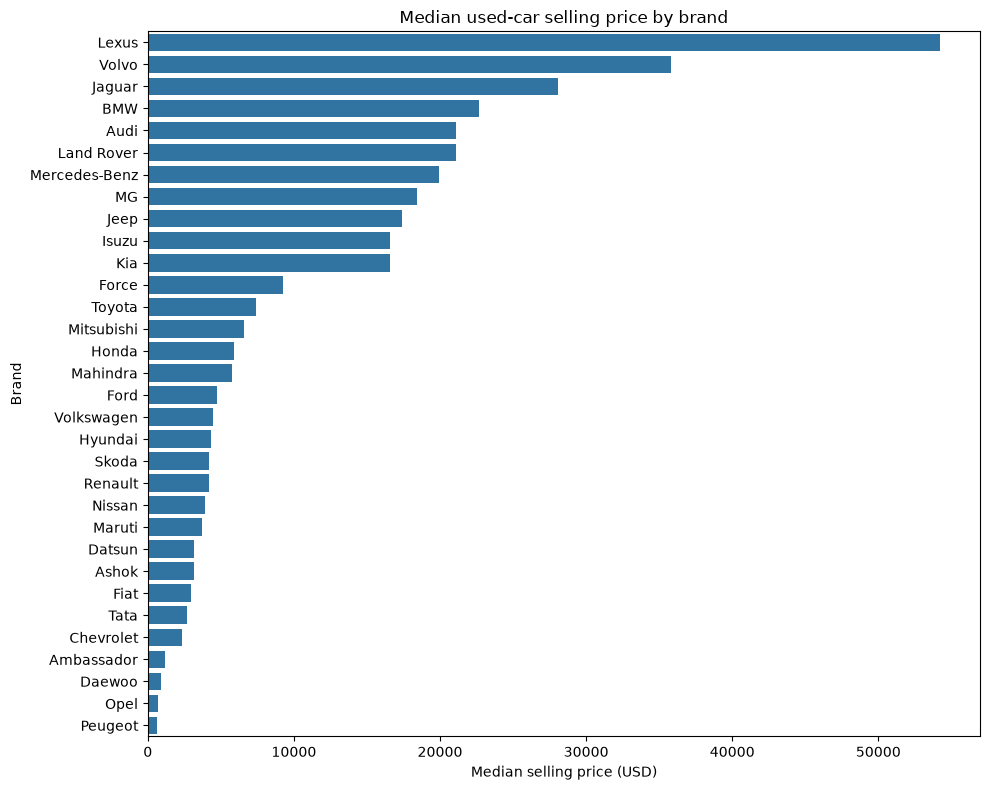

In [34]:
plt.figure(figsize=(10, 8))

sns.barplot(
    x=summary["median"],
    y=summary.index,
    errorbar=None
)

plt.xlabel("Median selling price (USD)")
plt.ylabel("Brand")
plt.title("Median used-car selling price by brand")
plt.tight_layout()
plt.ticklabel_format(axis="x", style="plain", useOffset=False)
plt.savefig("median_selling_price_by_brand.png", dpi=300, bbox_inches="tight")
plt.show()

## Sample Size Thresholds

At this point, the impact of small sample sizes becomes clear—some brands or vehicles are represented by so few entries that their presence can skew the overall dataset. Deciding whether to include or exclude these small-sample cases is important for maintaining the integrity of the analysis. For this project, I’ve chosen to retain all vehicles, even those with only a single sample, to provide a complete picture. However, I will also present results with both the full dataset and a filtered version that excludes brands or models with 20 or fewer samples. This approach highlights how small-sample data can influence findings while still allowing for comprehensive, transparent analysis.

In [35]:
counts = df['brand'].value_counts()
df['brand_counts'] = df['brand'].map(counts)
df_filtered = df[df['brand_counts'] > 20]

In [36]:
df_outliers = df[df['brand_counts'] < 20]
df_outliers.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,selling_price_usd,odometer_miles,fuel_efficiency_mpg,brand_counts
51,Mitsubishi Pajero Sport 4X4,2013,1090000,151000,Diesel,Dealer,Manual,First Owner,13.5 kmpl,2477 CC,175.56 bhp,400Nm@ 2000-2500rpm,7.0,Mitsubishi,11480.935328,93827.050028,32,11
132,Lexus ES 300h,2019,5150000,20000,Petrol,Dealer,Automatic,First Owner,22.37 kmpl,2487 CC,214.56 bhp,202Nm@ 3600-5200rpm,5.0,Lexus,54244.786181,12427.423845,53,1
133,Jaguar XF 2.0 Diesel Portfolio,2017,3200000,45000,Diesel,Dealer,Automatic,First Owner,19.33 kmpl,1999 CC,177 bhp,430Nm@ 1750-2500rpm,5.0,Jaguar,33705.498209,27961.703651,45,8
135,Land Rover Discovery Sport TD4 SE,2019,4500000,21000,Diesel,Dealer,Automatic,First Owner,12.83 kmpl,1999 CC,148.31 bhp,382nm@ 1750-2250rpm,7.0,Land Rover,47398.356857,13048.795037,30,3
142,MG Hector Sharp AT BSIV,2019,1750000,19000,Petrol,Dealer,Automatic,First Owner,13.96 kmpl,1451 CC,141 bhp,250Nm@ 1600-3600rpm,5.0,MG,18432.694333,11806.052653,33,3


In [37]:
df_large_brands = df[df['brand_counts'] > 20]
df_large_brands.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,selling_price_usd,odometer_miles,fuel_efficiency_mpg,brand_counts
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti,4739.835686,90409.508471,55,2165
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,Skoda,3897.198230,74564.543068,50,70
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,Honda,1664.208974,86991.966913,42,362
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,Hyundai,2369.917843,78914.141414,54,1267
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti,1369.285865,74564.543068,38,2165


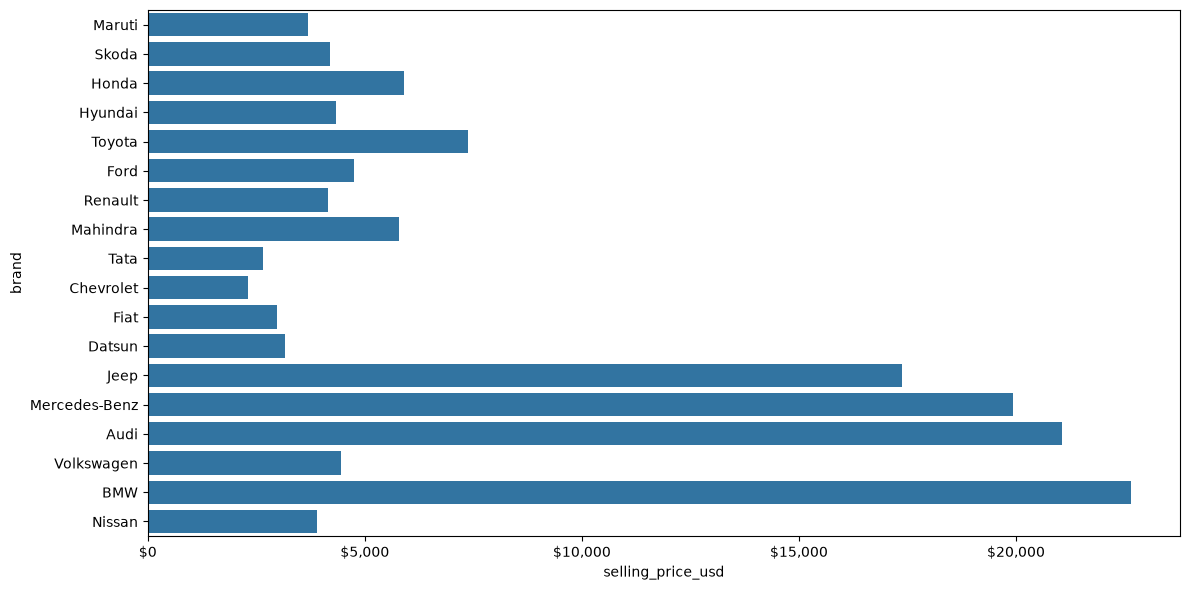

In [38]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_large_brands,
    y="brand",
    x="selling_price_usd", 
    estimator="median",
    errorbar=None,
)

plt.gca().xaxis.set_major_formatter("${x:,.0f}")
plt.savefig("median_selling_price_by_brand.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [39]:
df.head(1)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,selling_price_usd,odometer_miles,fuel_efficiency_mpg,brand_counts
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti,4739.835686,90409.508471,55,2165


In [40]:
brand_order = (
    df_large_brands.groupby("brand")["selling_price_usd"]
    .median()
    .sort_values(ascending=False)
    .index
)

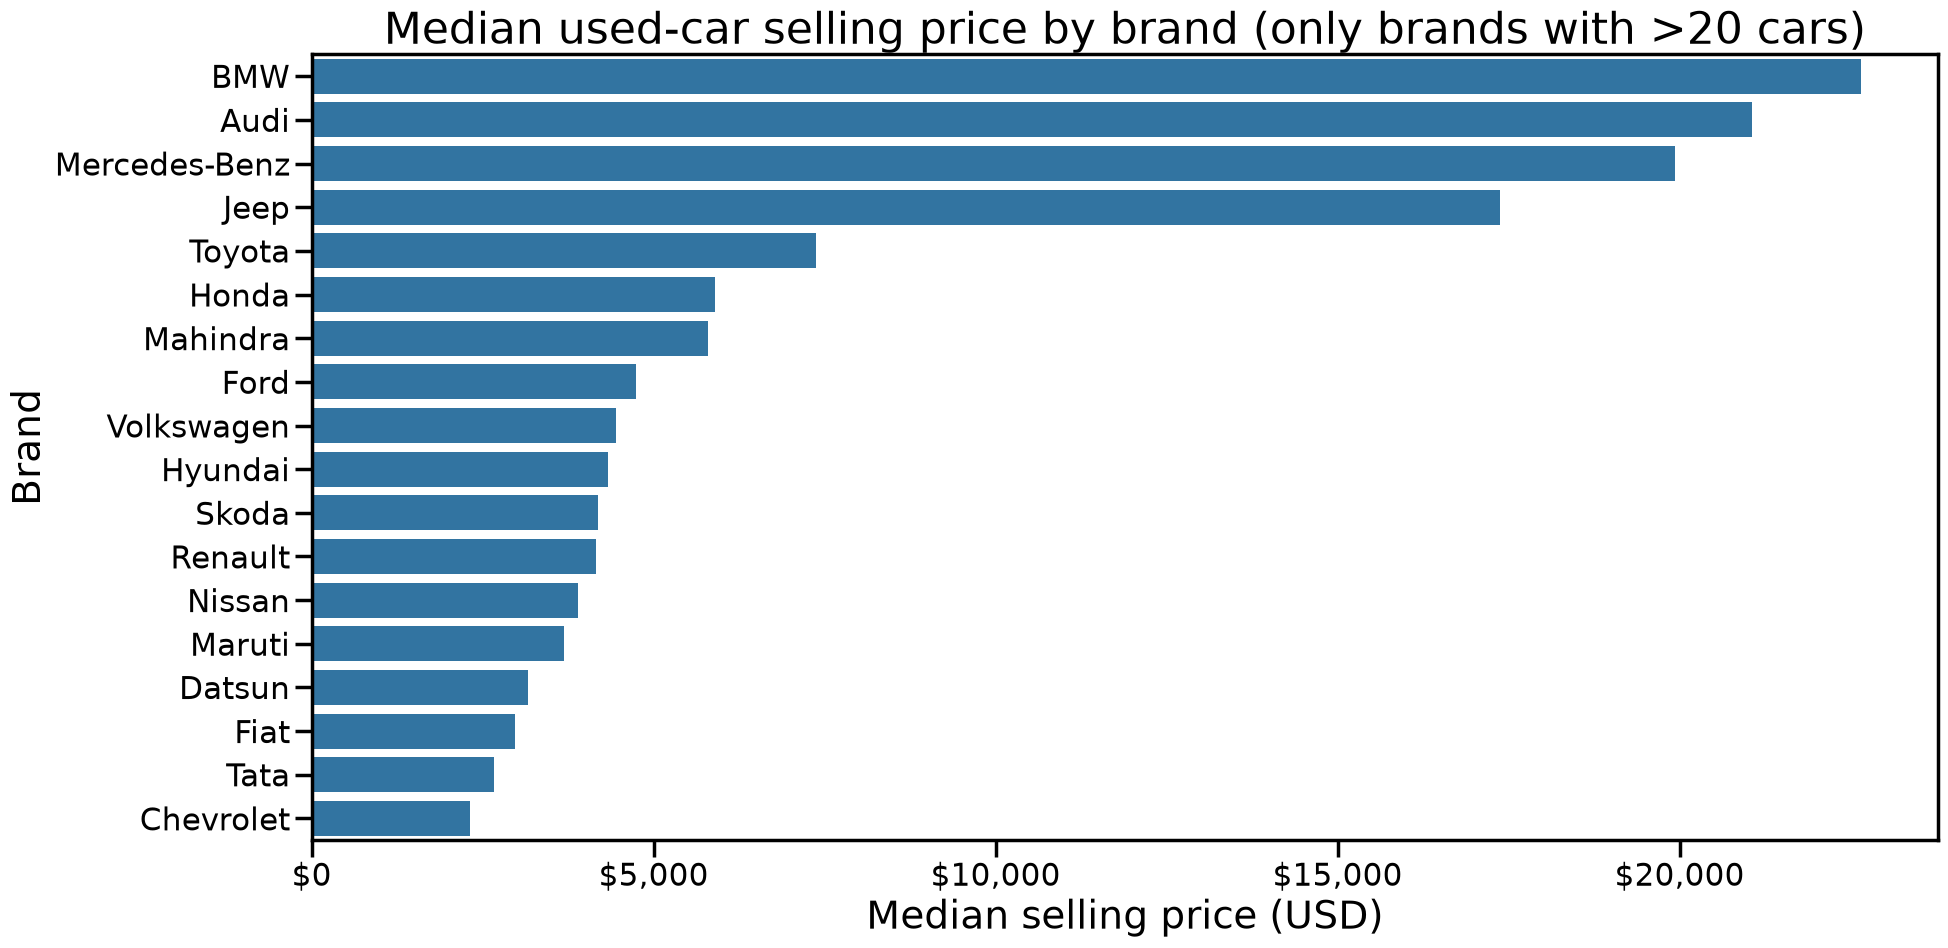

In [41]:
plt.figure(figsize=(20, 10))

sns.set_context("poster") 

sns.barplot(
    data=df_large_brands,
    y="brand",
    x="selling_price_usd",
    estimator="median",
    order=brand_order,  
    errorbar=None, ) 

plt.title("Median used-car selling price by brand (only brands with >20 cars)", fontsize=32)
plt.xlabel("Median selling price (USD)", fontsize=28)
plt.ylabel("Brand", fontsize=28)

plt.savefig("median_selling_price_by_brand_large.png", dpi=300, bbox_inches="tight")

plt.gca().xaxis.set_major_formatter("${x:,.0f}")
plt.tight_layout()
plt.show()

In [42]:
full_brand_order = (
    df.groupby("brand")["selling_price_usd"]
      .median()
      .sort_values()
      .index
)

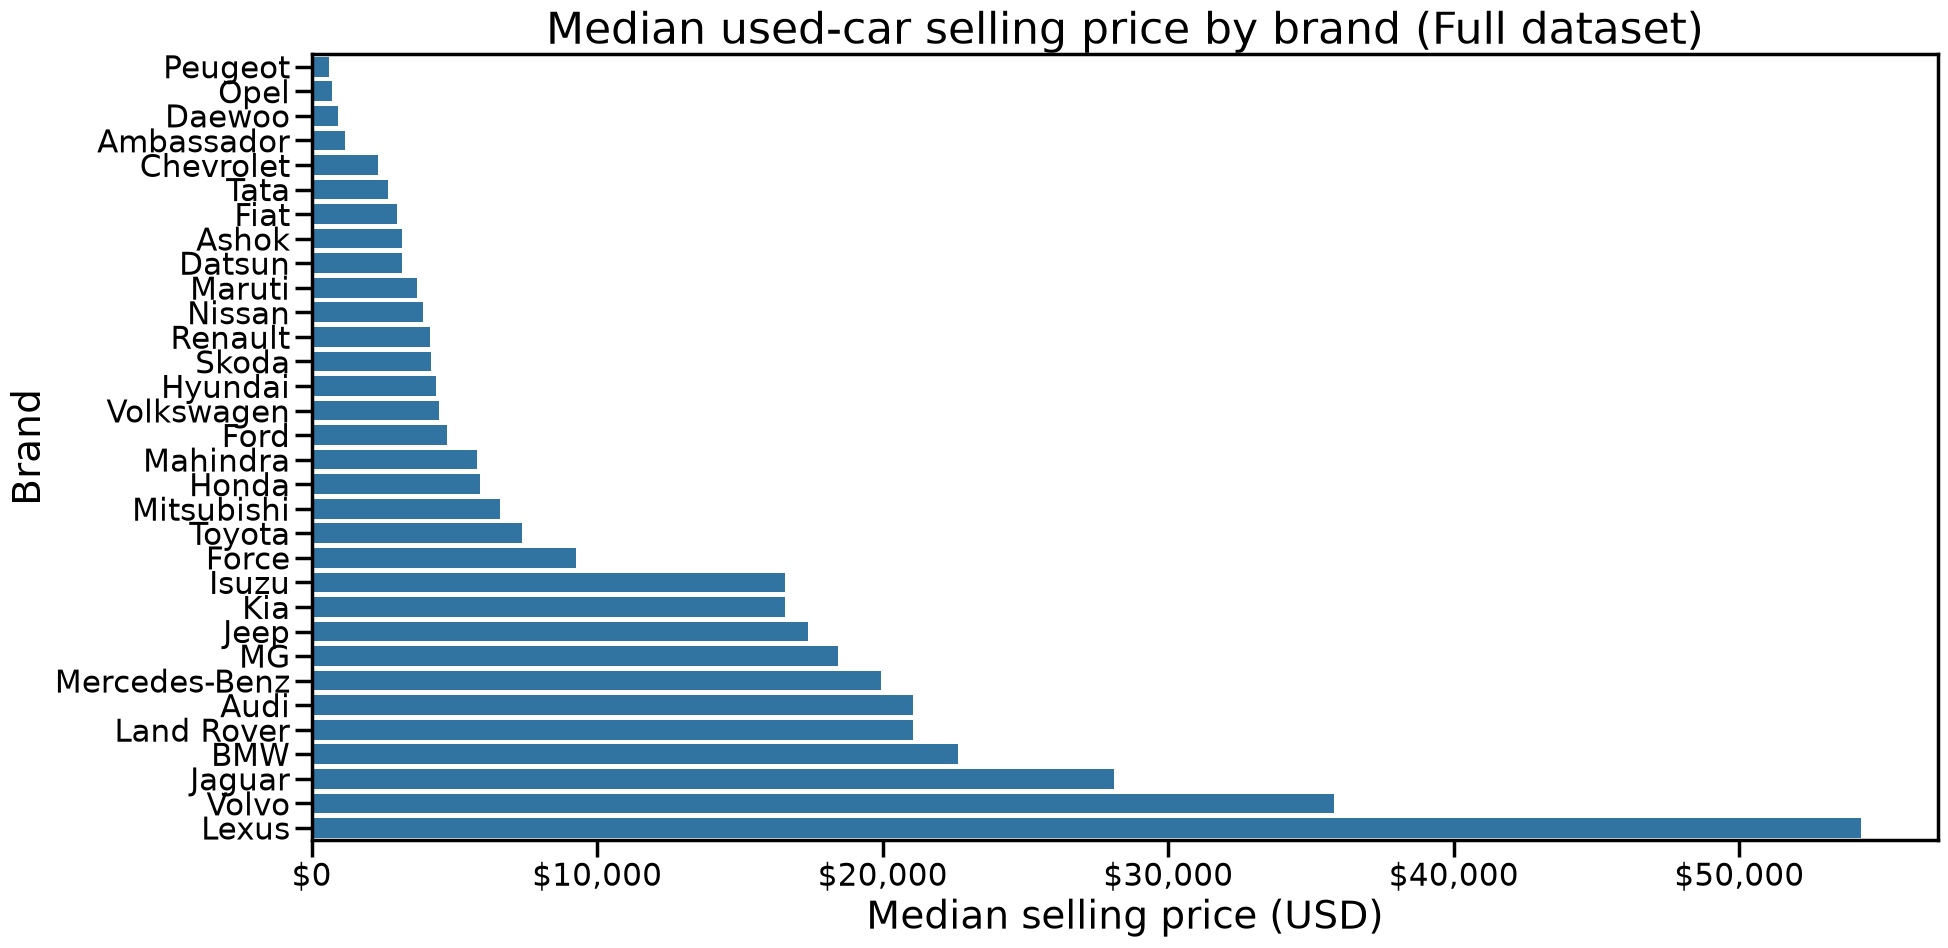

In [43]:
plt.figure(figsize=(20, 10))

sns.set_context("poster") 

sns.barplot(
    data=df,
    y="brand",
    x="selling_price_usd",
    estimator="median",
    order=full_brand_order, 
    errorbar=None, ) 

plt.title("Median used-car selling price by brand (Full dataset)", fontsize=32)
plt.xlabel("Median selling price (USD)", fontsize=28)
plt.ylabel("Brand", fontsize=28)

plt.savefig("median_selling_price_by_brand_full.png", dpi=300, bbox_inches="tight")

plt.gca().xaxis.set_major_formatter("${x:,.0f}")
plt.tight_layout()
plt.show()

## Interpreting small sample Impact



When comparing both the full and filtered charts, it becomes clear why excluding outliers or very small sample sizes is beneficial. Outliers and single-sample entries can dramatically inflate the maximum values, leading to misleading conclusions—such as Lexus appearing to have an unusually high used car selling price. However, this impression is not truly representative of the overall market, especially when key statistics like the median are being calculated from just one sample. By showing both views, the analysis highlights how outliers can distort results and underscores the importance of sample size when interpreting brand-specific data.

## Small issue

At this stage, I observed that although the brand label I created worked for most brands, there was an issue with "Land Rover." Specifically, 'Land' is not a brand on its own, and "Land Rover" was incorrectly split into two separate strings, resulting in only "Land" being recognized. To address this, I revised the code to ensure that multi-word brand names like "Land Rover" are properly identified and handled as a single entity.

In [44]:
df.isna().sum()

name                     0
year                     0
selling_price            0
km_driven                0
fuel                     0
seller_type              0
transmission             0
owner                    0
mileage                208
engine                 208
max_power              205
torque                 209
seats                  208
brand                    0
selling_price_usd        0
odometer_miles           0
fuel_efficiency_mpg    295
brand_counts             0
dtype: int64

## Evaluating data integrity 

To preserve data integrity, I conducted an additional review to confirm that no critical information was being overlooked. There are 295 null values in the fuel_efficiency_mpg column, which matches expectations: we began with 208 entries and later excluded 87 records measured in kilometers per kilogram (km/kg). Omitting these values is appropriate because km/kg measures distance per kilogram of fuel, whereas miles per gallon (MPG) measures distance per gallon. Accurately converting between these two units would be tough due to differences in fuel types and measurement standards.

In [45]:
df.head(1)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,selling_price_usd,odometer_miles,fuel_efficiency_mpg,brand_counts
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,Maruti,4739.835686,90409.508471,55,2165


In [46]:
df[["selling_price", "selling_price_usd"]].head()

,selling_price,selling_price_usd
0,450000,4739.835686
1,370000,3897.198230
2,158000,1664.208974
3,225000,2369.917843
4,130000,1369.285865


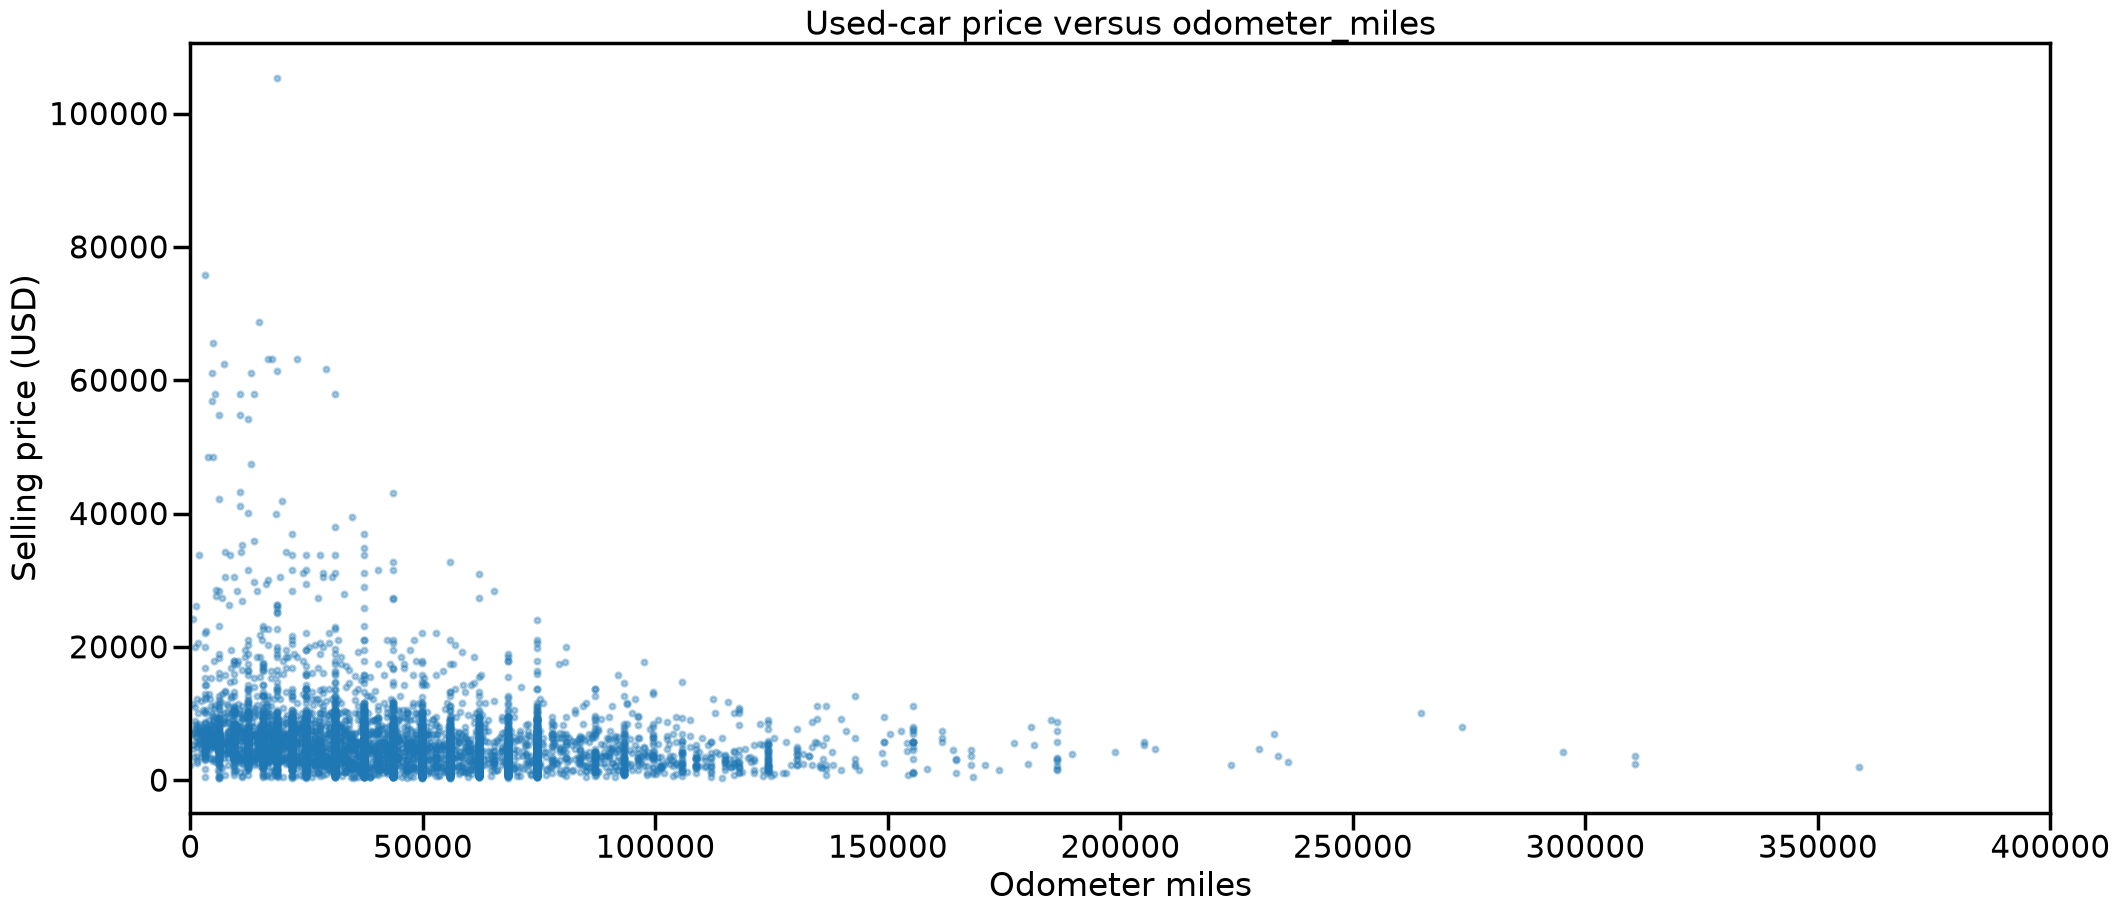

In [47]:
plot_data_2 = df.dropna(subset=["odometer_miles", "selling_price_usd"])


plt.figure(figsize=(24, 10))
plt.scatter(plot_data_2["odometer_miles"], plot_data_2["selling_price_usd"], alpha=0.35, s=15)
plt.title("Used-car price versus odometer_miles")
plt.xlabel("Odometer miles")
plt.ylabel("Selling_price")
plt.xlim(0, 400_000)
plt.ticklabel_format(axis="y", style="plain")
plt.ylabel("Selling price (USD)")

plt.savefig("used_car_price_vs_odometer_raw.png", dpi=300, bbox_inches="tight")

plt.show()

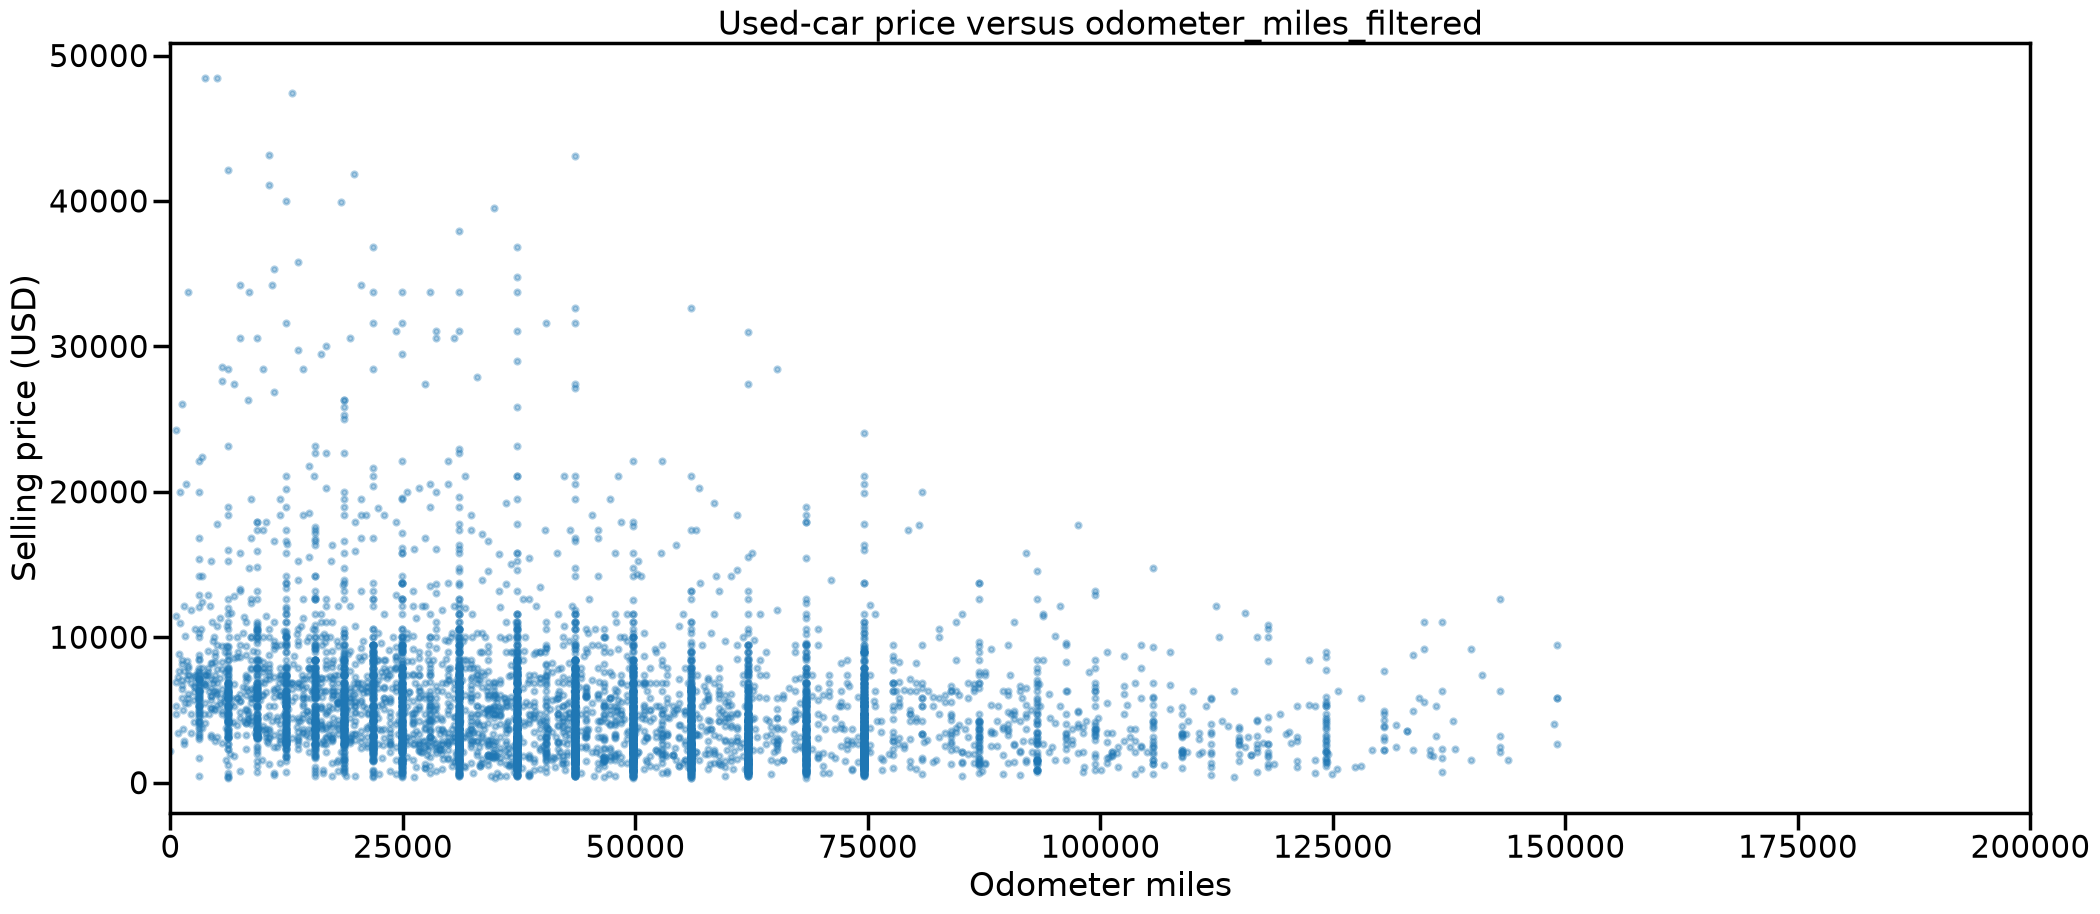

In [48]:
plot_data_2 = df.dropna(subset=["odometer_miles", "selling_price_usd"])

plot_filtered = plot_data_2[
    (plot_data_2["selling_price_usd"] <= 50000)  # Maximum price in USD
    & (plot_data_2["odometer_miles"] <= 150000)  # Maximum odometer miles
]

plt.figure(figsize=(24, 10))
plt.scatter(plot_filtered["odometer_miles"], plot_filtered["selling_price_usd"], alpha=0.35, s=15)
plt.title("Used-car price versus odometer_miles_filtered")
plt.xlabel("Odometer miles")
plt.ylabel("Selling_price")
plt.xlim(0, 200_000)
plt.ticklabel_format(axis="y", style="plain")
plt.ylabel("Selling price (USD)")

plt.savefig("used_car_price_vs_odometer_filtered.png", dpi=300, bbox_inches="tight")

plt.show()

In [49]:
filtered_correlation = plot_filtered["selling_price_usd"].corr(plot_filtered["odometer_miles"])
filtered_correlation

np.float64(-0.22473867464224861)

In [50]:
full_correlation = df["selling_price_usd"].corr(df["odometer_miles"])
full_correlation 

np.float64(-0.1656200740593886)

## Selling Price and Distance Driven

I checked whether cars with higher odometer readings usually sell for less money. To do this, I used a scatterplot to look for a pattern and calculated the correlation between distance driven and selling price. The result showed only a weak negative relationship, meaning that as cars are driven further, their prices go down a little, but not by much.

After limiting the analysis to cars priced at $50,000 or less with 150,000 miles or less, the correlation changed from approximately −0.166 to −0.224. The negative relationship became slightly stronger, but remained weak. The filtered chart helps show the pattern among cars within these limits.

In [51]:
fuel_type = df[df["fuel"].isin(["Petrol", "Diesel"])].copy()


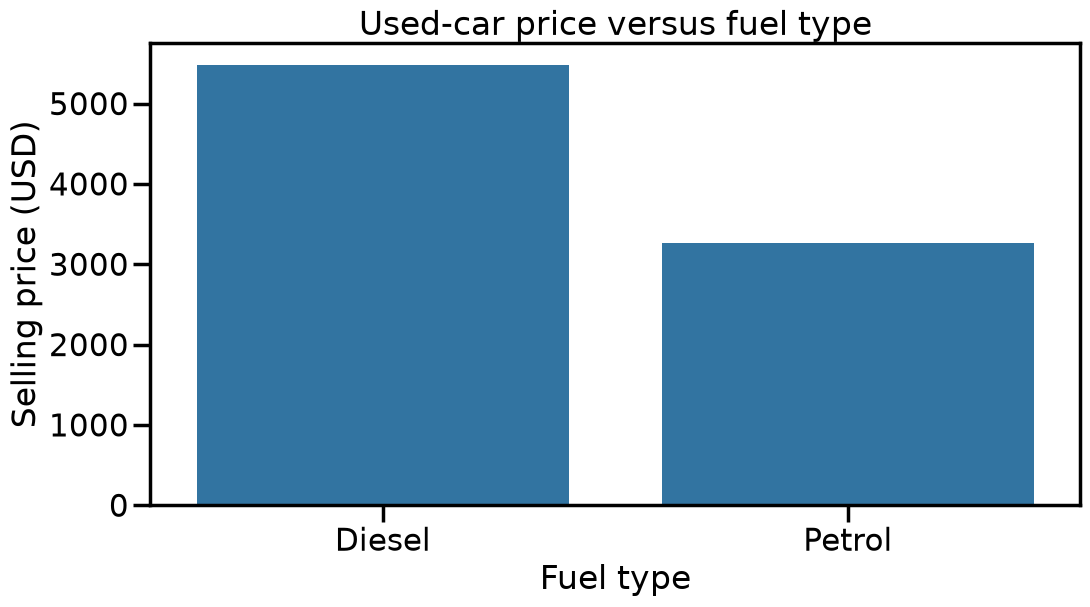

In [52]:
fuel_type = df[df["fuel"].isin(["Petrol", "Diesel"])].copy()

plot_data_3 = fuel_type.dropna(subset=["fuel", "selling_price_usd"])

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data_3,
    x="fuel",       
    y="selling_price_usd",       
    estimator="median",
    errorbar=None
)

plt.title("Used-car price versus fuel type")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (USD)")
plt.ticklabel_format(axis="y", style="plain")

plt.savefig("used_car_price_vs_fuel_type.png", dpi=300, bbox_inches="tight")
plt.show()

In [53]:
fuel_type.groupby("fuel")["selling_price_usd"].agg(["median", "count"])

,median,count
fuel,,
Diesel,5477.143459,3755
Petrol,3265.220139,3077


### Selling Price by Fuel Type

I analyzed the selling prices of diesel and petrol cars by comparing their median values. The median is a better measure than the mean in this context because it is not affected by unusually high-priced listings. The median selling price for diesel cars was about $5,477, while for petrol cars it was $3,265. This means diesel cars were roughly the median price was about 68% higher.”

This difference does not necessarily mean diesel fuel makes a car more valuable. Other characteristics, such as brand, model year, and distance driven, could help explain the difference.

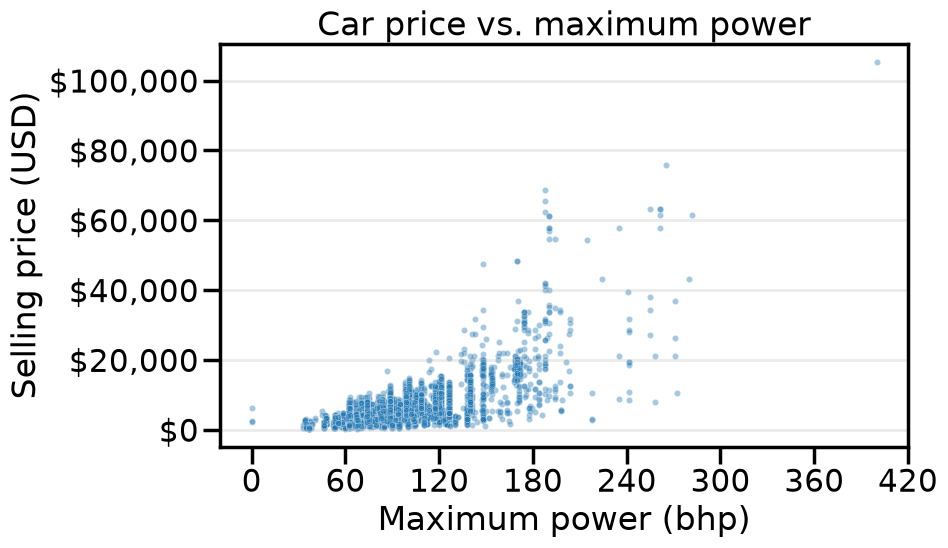

In [54]:
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

plot_df = df.copy()
plot_df["max_power"] = pd.to_numeric(
    plot_df["max_power"].astype(str).str.extract(r"([\d.]+)")[0],
    errors="coerce",
)
plot_df["selling_price_usd"] = pd.to_numeric(
    plot_df["selling_price_usd"], errors="coerce"
)
plot_df = plot_df.dropna(subset=["max_power", "selling_price_usd"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x="max_power",
    y="selling_price_usd",
    alpha=0.4,
    s=20,
    ax=ax,
)

ax.xaxis.set_major_locator(MaxNLocator(nbins=8))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set(title="Car price vs. maximum power",
       xlabel="Maximum power (bhp)",
       ylabel="Selling price (USD)")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

# Code generated with Copilot

In [55]:
df["power"] = pd.to_numeric(
    df["max_power"].str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

df["selling_price_usd"].corr(df["power"])

# Code generated with Copilot

np.float64(0.6915357139683028)

## Selling Price and Maximum Engine Power

Cars with higher maximum engine power, measured in brake horsepower (bhp), generally sold for higher prices. I found a correlation of +0.69 between engine power and selling price, indicating a much stronger linear relationship than what I observed between price and odometer mileage. However, even among cars with similar horsepower, selling prices varied considerably. This variation suggests that other factors—such as brand, model year, condition, and additional features—also play a significant role in determining price.

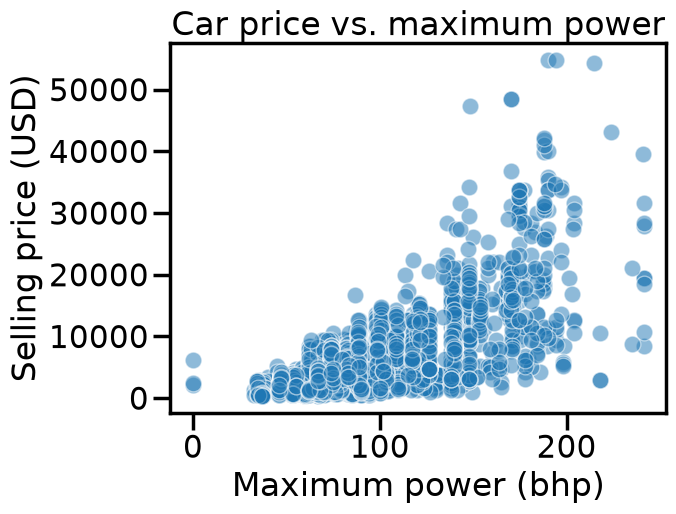

In [56]:
filtered_power = df[
    (df["power"] <= 250) &
    (df["selling_price_usd"] <= 55_000)
]

sns.scatterplot(
    data=filtered_power,
    x="power",
    y="selling_price_usd",
    alpha=0.5
)

plt.xlabel("Maximum power (bhp)")
plt.ylabel("Selling price (USD)")
plt.title("Car price vs. maximum power")
plt.show()

# Code generated with Copilot

### Selling Price and Maximum Engine Power (Filtered View)

To better illustrate the main cluster of data, I filtered the chart to only include cars with engine power below 250 bhp and prices under $55,000. This closer view makes it easier to observe that at lower power levels, car prices are grouped more closely together, indicating less variation. In contrast, as engine power increases to around 150–200 bhp, selling prices become more dispersed, suggesting greater price variability among higher-powered vehicles.

In [57]:
df['max_power'].isnull().sum()

np.int64(205)